# Data Visualization 

Data visualization demonstration with **Seaborn** and **Matplotlib**, applied to eight real-world datasets. 

| Section | Plot types | Dataset |
|---|---|---|
| 1. Trends over time | Line charts | FIFA rankings, Spotify streams, LA museum visitors |
| 2. Comparing categories | Bar charts, heatmaps | US flight delays, IGN game scores |
| 3. Relationships | Scatter, regression, swarm plots | Medical insurance, candy rankings |
| 4. Distributions | Histograms, KDE, joint plots | Iris, breast cancer |
| 5. Styling | Seaborn themes | Spotify streams |
| 6. Amazon Data | Cleaning + histogram, scatter, bar | Amazon product listings |



## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.plotting.register_matplotlib_converters()

data_dir = Path("Data_105") 

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

## 1. Trends over Time: Line Charts

Line charts are the natural choice for showing how one or more measures change over time.

### 1.1 FIFA world rankings
Ranking history of six national teams (a **lower** value is a **better** rank).

In [2]:
fifa_data = pd.read_csv(data_dir / "fifa.csv", index_col="Date", parse_dates=True)
fifa_data.head()

,ARG,BRA,ESP,FRA,GER,ITA
Date,,,,,,
1993-08-08,5.0,8.0,13.0,12.0,1.0,2.0
1993-09-23,12.0,1.0,14.0,7.0,5.0,2.0
1993-10-22,9.0,1.0,7.0,14.0,4.0,3.0
1993-11-19,9.0,4.0,7.0,15.0,3.0,1.0
1993-12-23,8.0,3.0,5.0,15.0,1.0,2.0


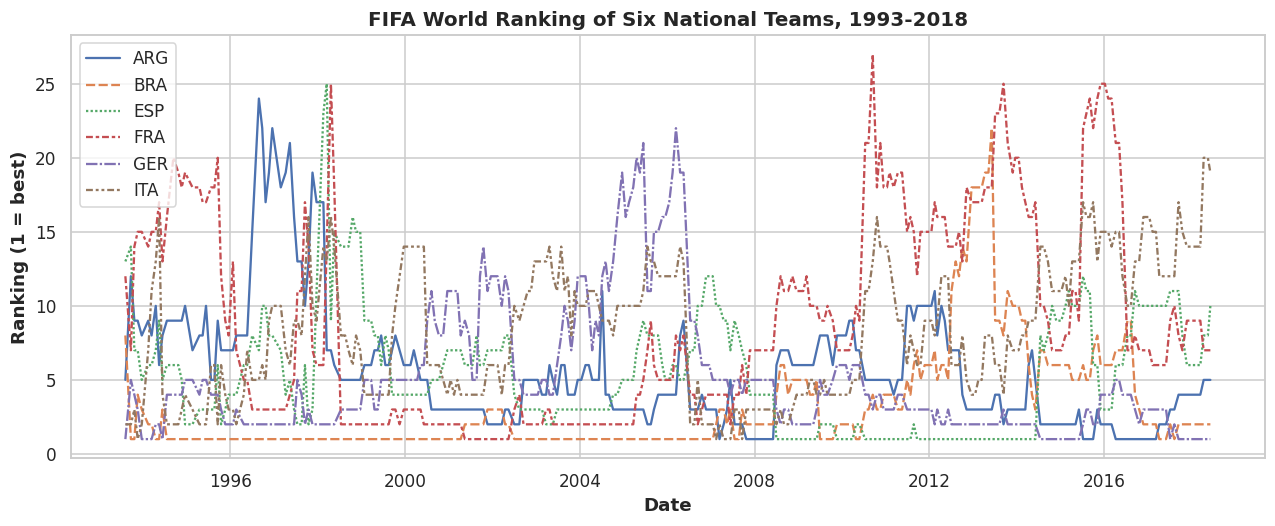

In [3]:
plt.figure(figsize=(14, 5))
plt.title("FIFA World Ranking of Six National Teams, 1993-2018")
sns.lineplot(data=fifa_data)
plt.xlabel("Date", fontweight="bold")
plt.ylabel("Ranking (1 = best)", fontweight="bold")
plt.show()

### 1.2 Spotify daily streams
Daily global streams of five popular songs during 2017-2018.

In [4]:
spotify_data = pd.read_csv(data_dir / "spotify.csv", index_col="Date", parse_dates=True)
spotify_data.head()

,Shape of You,Despacito,Something Just Like This,HUMBLE.,Unforgettable
Date,,,,,
2017-01-06,12287078,NaN,NaN,NaN,NaN
2017-01-07,13190270,NaN,NaN,NaN,NaN
2017-01-08,13099919,NaN,NaN,NaN,NaN
2017-01-09,14506351,NaN,NaN,NaN,NaN
2017-01-10,14275628,NaN,NaN,NaN,NaN


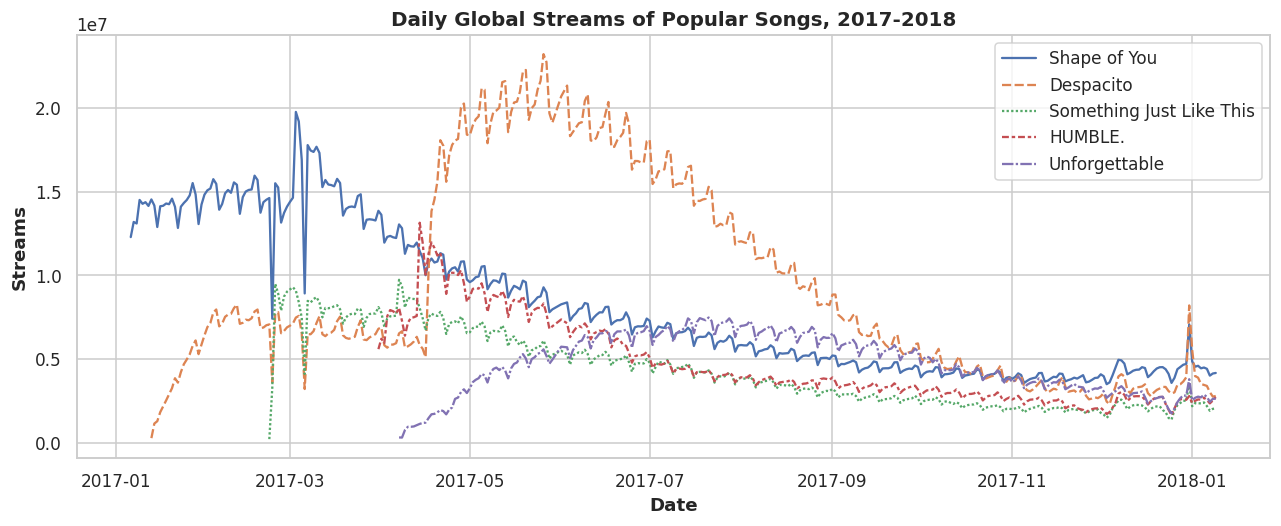

In [5]:
plt.figure(figsize=(14, 5))
plt.title("Daily Global Streams of Popular Songs, 2017-2018")
sns.lineplot(data=spotify_data)
plt.xlabel("Date", fontweight="bold")
plt.ylabel("Streams", fontweight="bold")
plt.show()

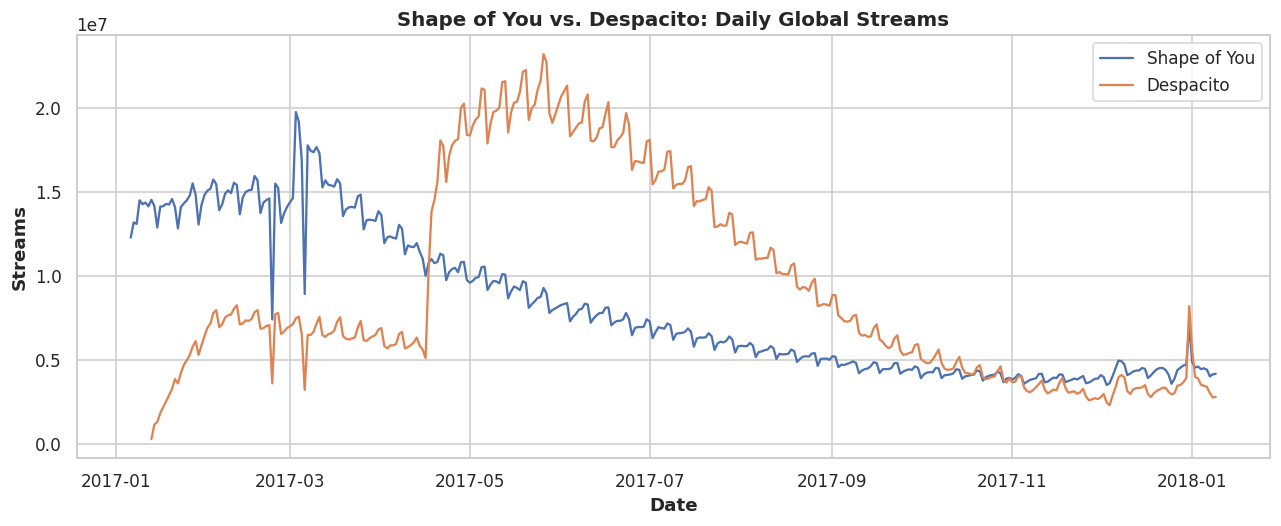

In [6]:
plt.figure(figsize=(14, 5))
plt.title("Shape of You vs. Despacito: Daily Global Streams")

for song in ["Shape of You", "Despacito"]:
    sns.lineplot(data=spotify_data[song], label=song)

plt.xlabel("Date", fontweight="bold")
plt.ylabel("Streams", fontweight="bold")
plt.show()

### 1.3 Los Angeles museum visitors
Monthly visitor counts for four museums, 2014-2018.

In [7]:
museum_data = pd.read_csv(data_dir / "museum_visitors.csv", index_col="Date", parse_dates=True)
museum_data.tail()

,Avila Adobe,Firehouse Museum,Chinese American Museum,America Tropical Interpretive Center
Date,,,,
2018-07-01,23136,4191,2620,4718
2018-08-01,20815,4866,2409,3891
2018-09-01,21020,4956,2146,3180
2018-10-01,19280,4622,2364,3775
2018-11-01,17163,4082,2385,4562


In [8]:
july_2018 = museum_data.loc["2018-07-01", "Chinese American Museum"]
print(f"Chinese American Museum visitors, July 2018: {july_2018:,}")

oct_2018 = museum_data.loc["2018-10-01"]
gap = oct_2018["Avila Adobe"] - oct_2018["Firehouse Museum"]
print(f"Avila Adobe received {gap:,} more visitors than the Firehouse Museum in October 2018")

Chinese American Museum visitors, July 2018: 2,620
Avila Adobe received 14,658 more visitors than the Firehouse Museum in October 2018


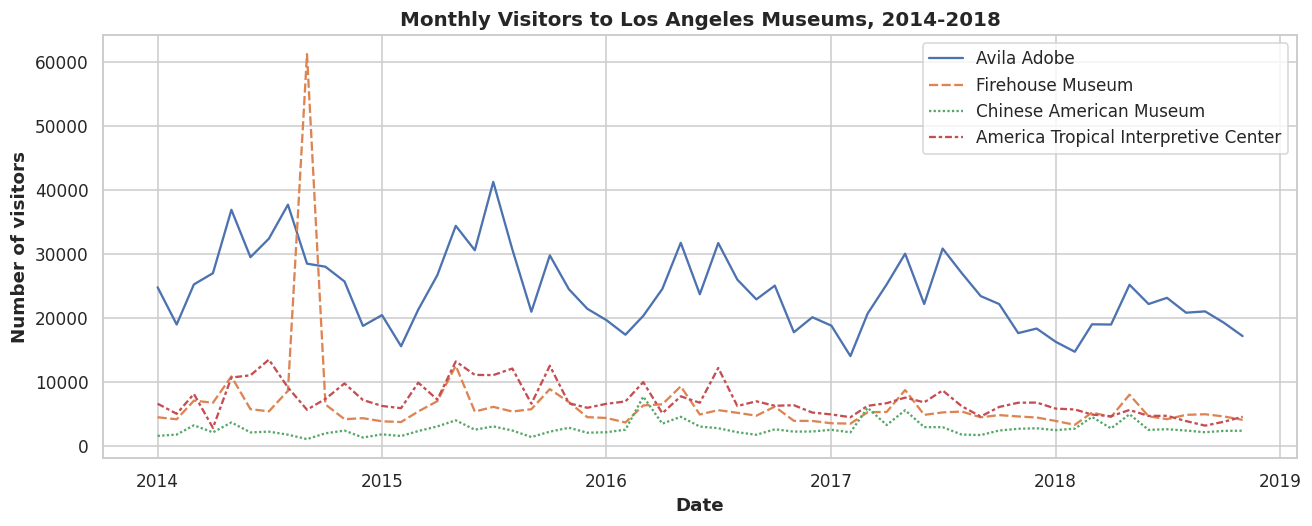

In [9]:
plt.figure(figsize=(14, 5))
plt.title("Monthly Visitors to Los Angeles Museums, 2014-2018")
sns.lineplot(data=museum_data)
plt.xlabel("Date", fontweight="bold")
plt.ylabel("Number of visitors", fontweight="bold")
plt.show()

**Takeaway:** Avila Adobe consistently draws the most visitors. The Firehouse Museum shows a single, extreme spike in late 2014 that stands out from its otherwise steady pattern.

## 2. Comparing Categories: Bar Charts and Heatmaps

Bar charts compare a value across categories; heatmaps extend the idea to two categorical dimensions at once.

### 2.1 Flight delays
Average arrival delay (minutes) per airline and month. Negative values imply early arrivals.

In [10]:
flight_data = pd.read_csv(data_dir / "flight_delays.csv", index_col="Month")
flight_data.head()

,AA,AS,B6,DL,EV,F9,HA,MQ,NK,OO,UA,US,VX,WN
Month,,,,,,,,,,,,,,
1,6.955843,-0.320888,7.347281,-2.043847,8.537497,18.357238,3.512640,18.164974,11.398054,10.889894,6.352729,3.107457,1.420702,3.389466
2,7.530204,-0.782923,18.657673,5.614745,10.417236,27.424179,6.029967,21.301627,16.474466,9.588895,7.260662,7.114455,7.784410,3.501363
3,6.693587,-0.544731,10.741317,2.077965,6.730101,20.074855,3.468383,11.018418,10.039118,3.181693,4.892212,3.330787,5.348207,3.263341
4,4.931778,-3.009003,2.780105,0.083343,4.821253,12.640440,0.011022,5.131228,8.766224,3.223796,4.376092,2.660290,0.995507,2.996399
5,5.173878,-1.716398,-0.709019,0.149333,7.724290,13.007554,0.826426,5.466790,22.397347,4.141162,6.827695,0.681605,7.102021,5.680777


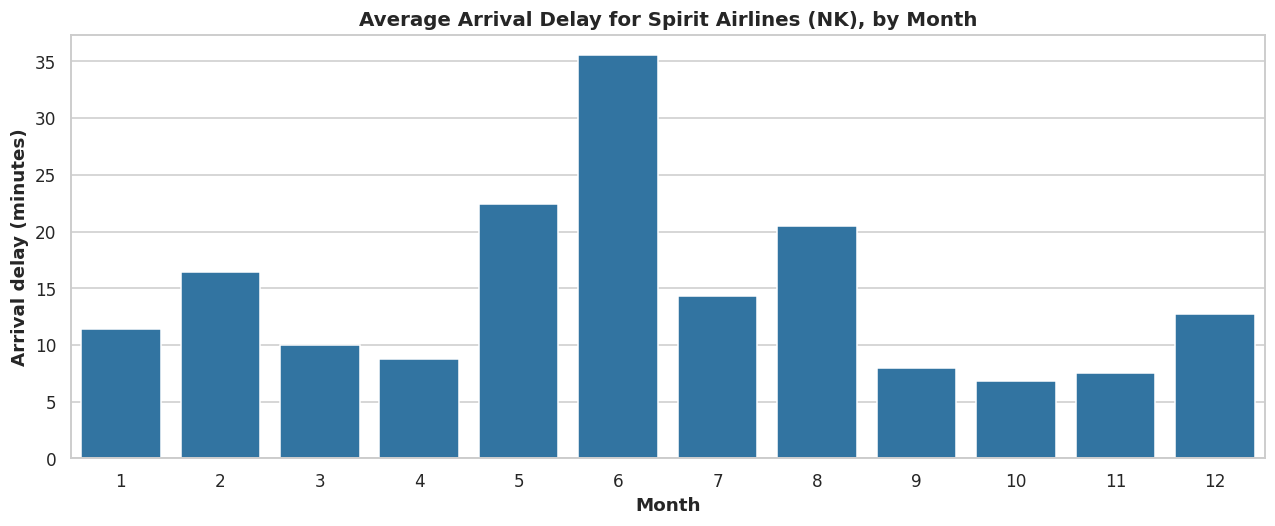

In [11]:
plt.figure(figsize=(14, 5))
plt.title("Average Arrival Delay for Spirit Airlines (NK), by Month")
sns.barplot(x=flight_data.index, y=flight_data["NK"], color="tab:blue")
plt.xlabel("Month", fontweight="bold")
plt.ylabel("Arrival delay (minutes)", fontweight="bold")
plt.show()

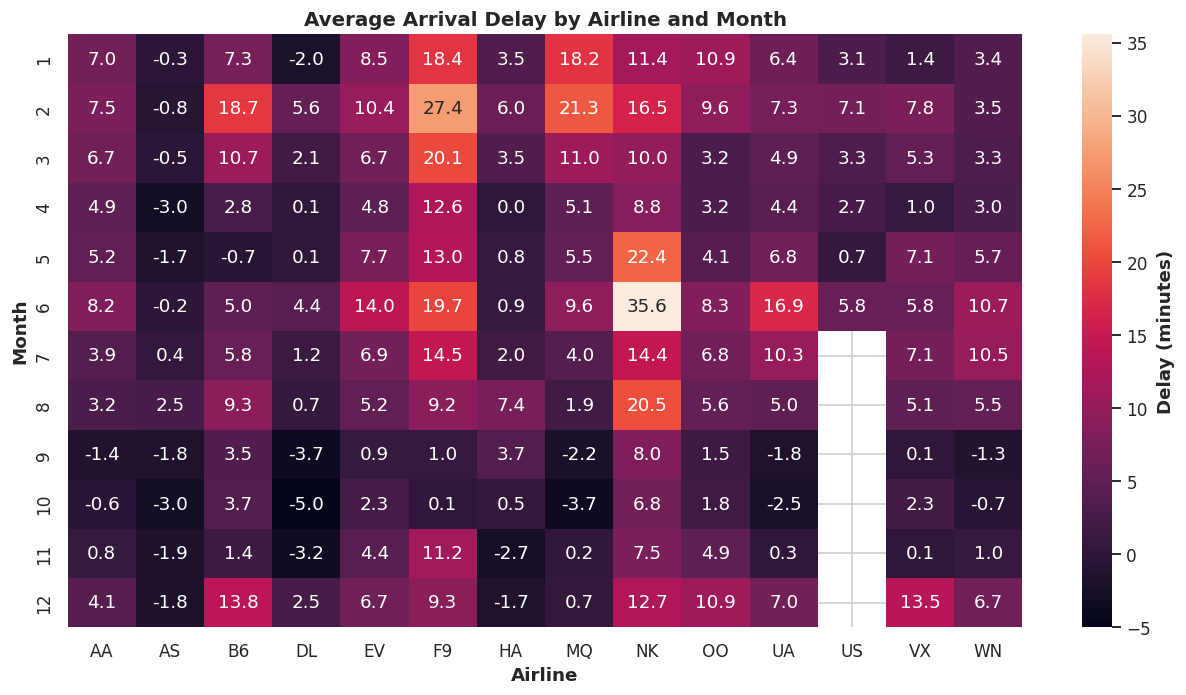

In [12]:
plt.figure(figsize=(14, 7))
plt.title("Average Arrival Delay by Airline and Month")
ax = sns.heatmap(flight_data, annot=True, fmt=".1f", cmap="rocket", cbar_kws={"label": "Delay (minutes)"})
cbar = ax.collections[0].colorbar
cbar.set_label("Delay (minutes)", fontweight="bold")
plt.xlabel("Airline", fontweight="bold")
plt.ylabel("Month", fontweight="bold")
plt.show()

**Takeaway:** Delays peak for several carriers in summer (June) and winter (February), while autumn months are the most punctual. A few airlines, such as AS, average close to zero or even arrive early.

### 2.2 IGN game review scores
Average review score for each game genre on each platform.

In [13]:
ign_data = pd.read_csv(data_dir / "ign_scores.csv", index_col="Platform")
ign_data.head()

,Action,"Action, Adventure",Adventure,Fighting,Platformer,Puzzle,RPG,Racing,Shooter,Simulation,Sports,Strategy
Platform,,,,,,,,,,,,
Dreamcast,6.882857,7.511111,6.281818,8.200000,8.340000,8.088889,7.700000,7.042500,7.616667,7.628571,7.272222,6.433333
Game Boy Advance,6.373077,7.507692,6.057143,6.226316,6.970588,6.532143,7.542857,6.657143,6.444444,6.928571,6.694444,7.175000
Game Boy Color,6.272727,8.166667,5.307692,4.500000,6.352941,6.583333,7.285714,5.897436,4.500000,5.900000,5.790698,7.400000
GameCube,6.532584,7.608333,6.753846,7.422222,6.665714,6.133333,7.890909,6.852632,6.981818,8.028571,7.481319,7.116667
Nintendo 3DS,6.670833,7.481818,7.414286,6.614286,7.503448,8.000000,7.719231,6.900000,7.033333,7.700000,6.388889,7.900000


In [14]:
best_pc = ign_data.loc["PC"].max()
vita_scores = ign_data.loc["PlayStation Vita"]
worst_vita_genre = vita_scores.idxmin()

print(f"Highest average genre score on PC: {best_pc:.2f}")
print(f"Lowest-scoring genre on PlayStation Vita: {worst_vita_genre} ({vita_scores.min():.2f})")

Highest average genre score on PC: 7.76
Lowest-scoring genre on PlayStation Vita: Simulation (5.72)


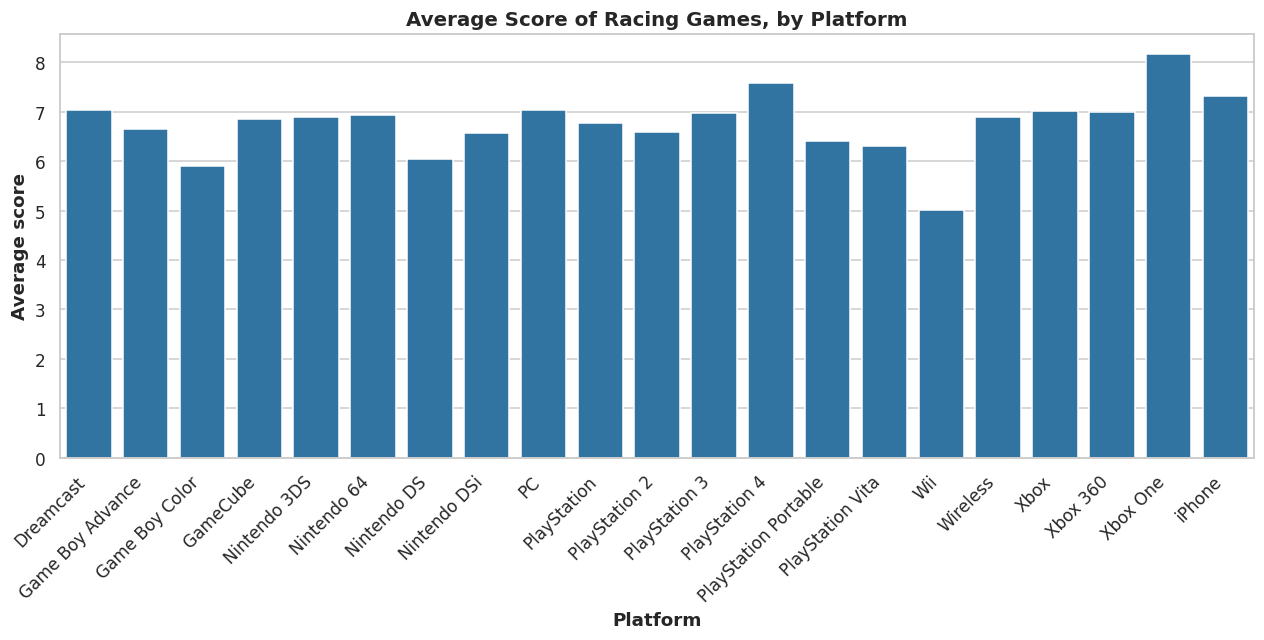

In [15]:
plt.figure(figsize=(14, 5))
plt.title("Average Score of Racing Games, by Platform")
sns.barplot(x=ign_data.index, y=ign_data["Racing"], color="tab:blue")
plt.xlabel("Platform", fontweight="bold")
plt.ylabel("Average score", fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.show()

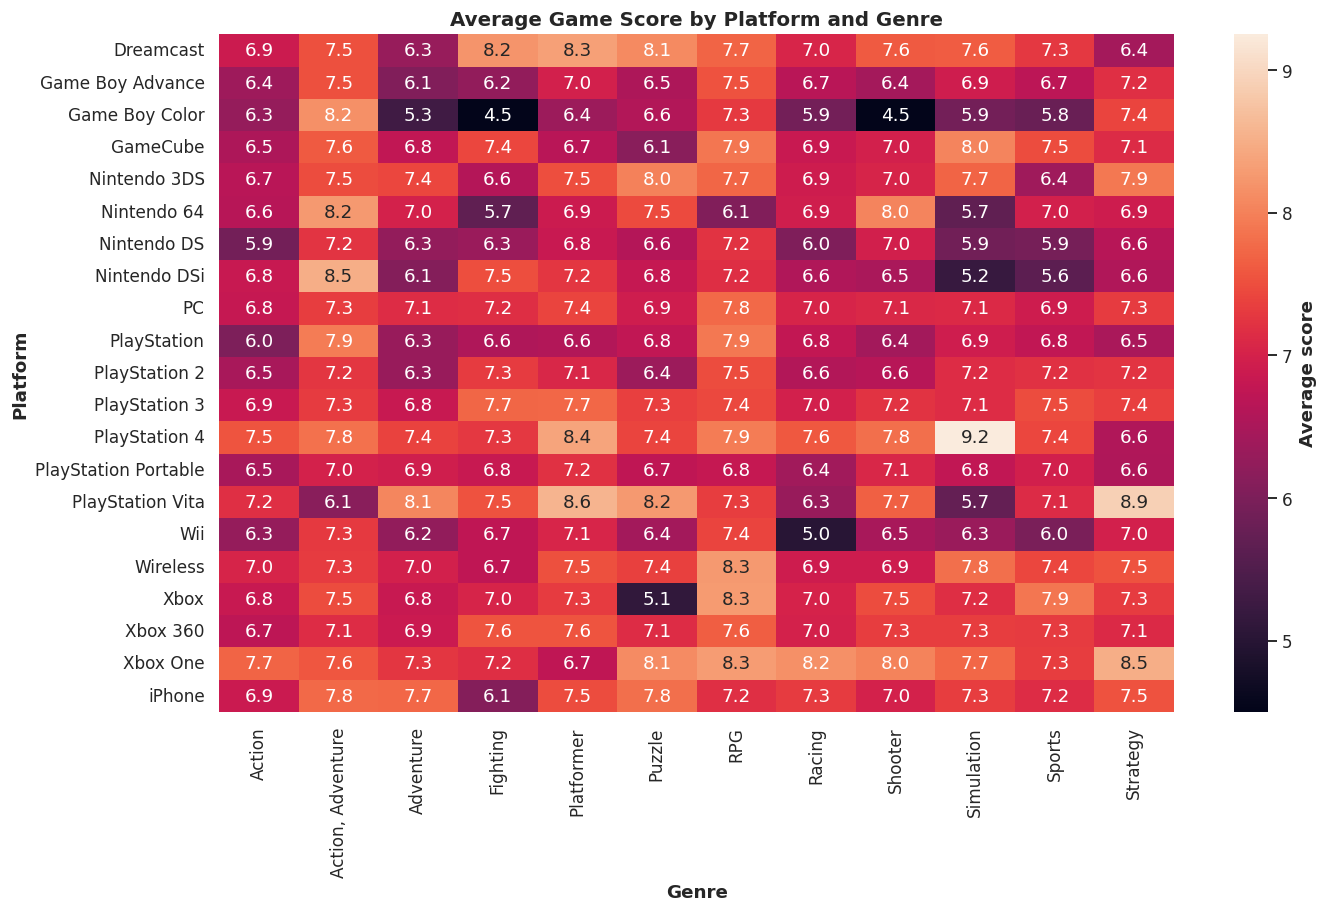

In [16]:
plt.figure(figsize=(14, 8))
plt.title("Average Game Score by Platform and Genre")
ax = sns.heatmap(ign_data, annot=True, fmt=".1f", cmap="rocket", cbar_kws={"label": "Average score"})
cbar = ax.collections[0].colorbar
cbar.set_label("Average score", fontweight="bold")
plt.xlabel("Genre", fontweight="bold")
plt.ylabel("Platform", fontweight="bold")
plt.show()

## 3. Relationships: Scatter Plots

Scatter plots reveal whether two numeric variables move together. Adding a colour dimension (`hue`) or a categorical axis can expose hidden structure.

### 3.1 Medical insurance charges
How do BMI and smoking status relate to insurance charges?

In [17]:
insurance_data = pd.read_csv(data_dir / "insurance.csv")
insurance_data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


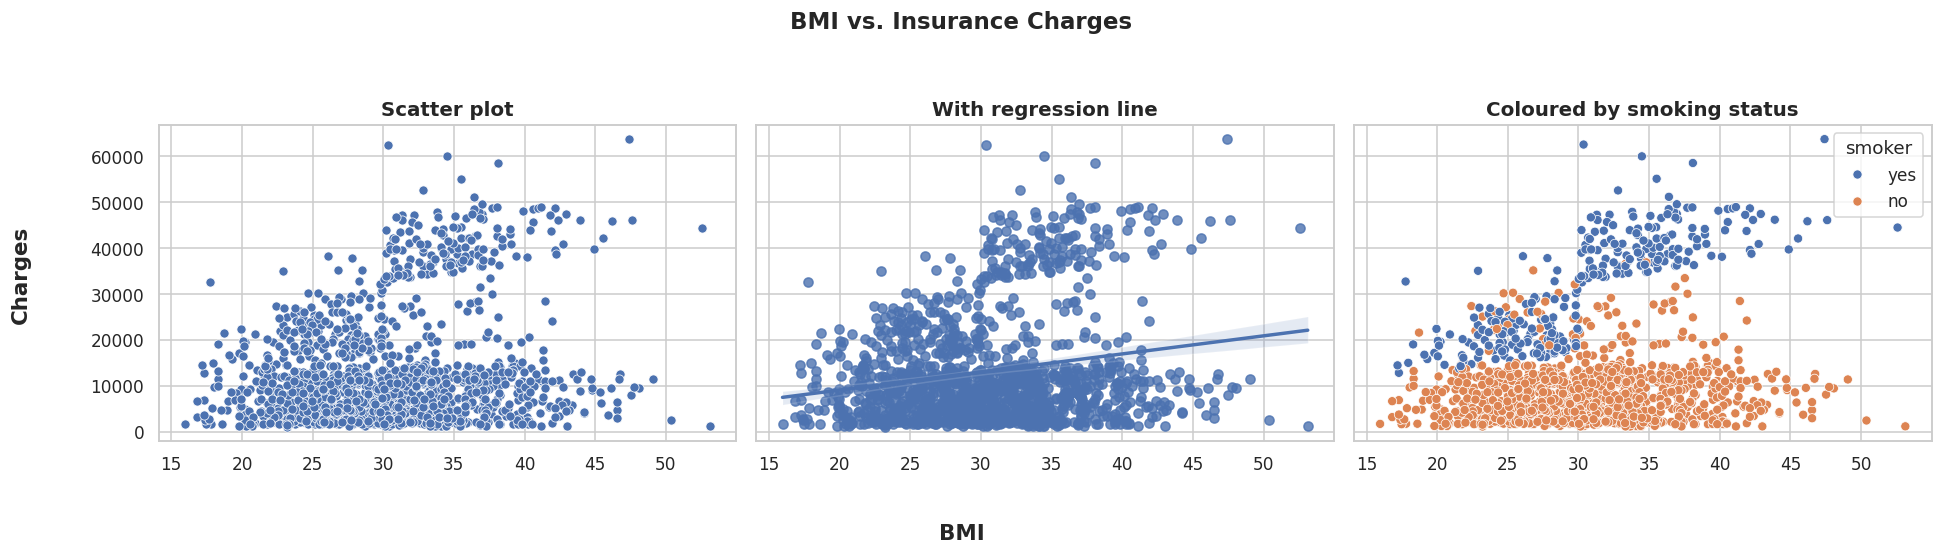

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.scatterplot(data=insurance_data, x="bmi", y="charges", ax=axes[0])
axes[0].set_title("Scatter plot")

sns.regplot(data=insurance_data, x="bmi", y="charges", ax=axes[1])
axes[1].set_title("With regression line")

sns.scatterplot(data=insurance_data, x="bmi", y="charges", hue="smoker", ax=axes[2])
axes[2].set_title("Coloured by smoking status")

# Main title
fig.suptitle("BMI vs. Insurance Charges", fontsize=15, fontweight="bold")

for ax in axes:
    ax.set_ylabel("")
    ax.set_xlabel("")

fig.supxlabel("BMI", fontsize=14, fontweight="bold")
fig.supylabel("Charges", fontsize=14, fontweight="bold")

plt.tight_layout(rect=[0.03, 0.03, 1, 0.93])
plt.show()

`lmplot` fits a separate regression line per group, which makes the interaction between BMI and smoking status clear:

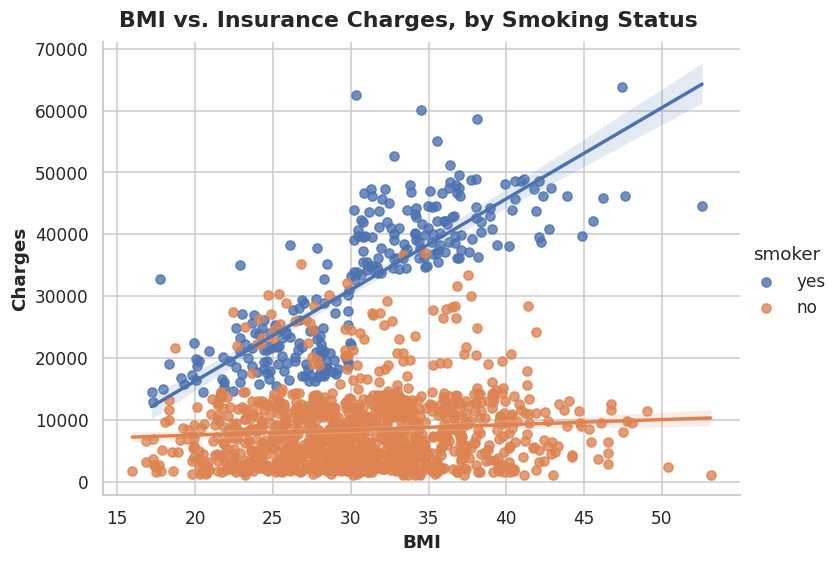

In [19]:
g = sns.lmplot(data=insurance_data, x="bmi", y="charges", hue="smoker", height=5, aspect=1.4)
g.figure.suptitle("BMI vs. Insurance Charges, by Smoking Status", y=1.02, fontweight="bold")
plt.xlabel("BMI", fontweight="bold")
plt.ylabel("Charges", fontweight="bold")
plt.show()

A **swarm plot** shows every observation while comparing a numeric variable across a categorical one:

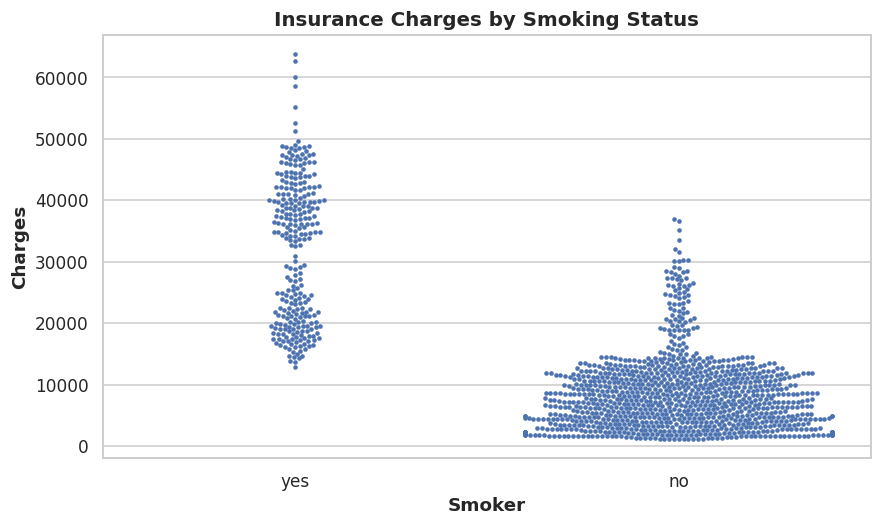

In [20]:
plt.figure(figsize=(9, 5))
plt.title("Insurance Charges by Smoking Status")
sns.swarmplot(data=insurance_data, x="smoker", y="charges", size=3)
plt.xlabel("Smoker", fontweight="bold")
plt.ylabel("Charges", fontweight="bold")
plt.show()

**Takeaway:** For non-smokers, charges barely change with BMI. For smokers, charges rise steeply as BMI increases, and smokers pay substantially more overall.

### 3.2 Candy rankings
What makes a candy popular? `winpercent` is the share of head-to-head matchups a candy wins.

In [21]:
candy = pd.read_csv(data_dir / "candy.csv", index_col="id")
candy.head()

,competitorname,chocolate,fruity,caramel,peanutyalmondy,nougat,crispedricewafer,hard,bar,pluribus,sugarpercent,pricepercent,winpercent
id,,,,,,,,,,,,,
0,100 Grand,Yes,No,Yes,No,No,Yes,No,Yes,No,0.732,0.860,66.971725
1,3 Musketeers,Yes,No,No,No,Yes,No,No,Yes,No,0.604,0.511,67.602936
2,Air Heads,No,Yes,No,No,No,No,No,No,No,0.906,0.511,52.341465
3,Almond Joy,Yes,No,No,Yes,No,No,No,Yes,No,0.465,0.767,50.347546
4,Baby Ruth,Yes,No,Yes,Yes,Yes,No,No,Yes,No,0.604,0.767,56.914547


In [22]:
top_candy = candy.loc[candy["winpercent"].idxmax()]
sweetest = candy.loc[candy["sugarpercent"].idxmax()]

print(f"Most popular candy: {top_candy['competitorname']} ({top_candy['winpercent']:.1f}% win rate)")
print(f"Highest sugar percentile: {sweetest['competitorname']} ({sweetest['sugarpercent']:.1%})")

Most popular candy: Reese's Peanut Butter cup (84.2% win rate)
Highest sugar percentile: Reese's stuffed with pieces (98.8%)


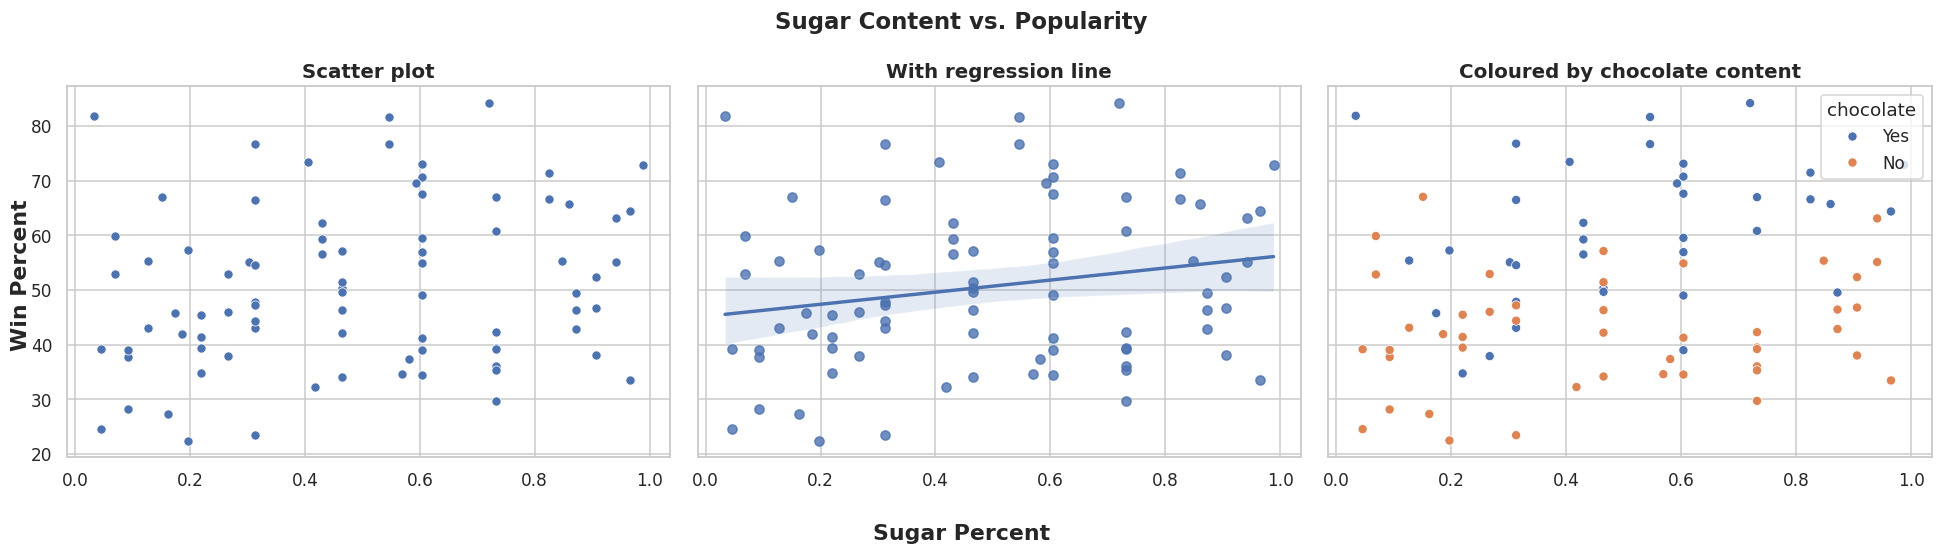

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.scatterplot(data=candy, x="sugarpercent", y="winpercent", ax=axes[0])
axes[0].set_title("Scatter plot")

sns.regplot(data=candy, x="sugarpercent", y="winpercent", ax=axes[1])
axes[1].set_title("With regression line")

sns.scatterplot(data=candy, x="sugarpercent", y="winpercent", hue="chocolate", ax=axes[2])
axes[2].set_title("Coloured by chocolate content")

fig.suptitle("Sugar Content vs. Popularity", fontsize=15, fontweight="bold")
for ax in axes:
    ax.set_ylabel("")
    ax.set_xlabel("")

fig.supxlabel("Sugar Percent", fontweight="bold")
fig.supylabel("Win Percent", fontweight="bold")
plt.tight_layout()
plt.show()

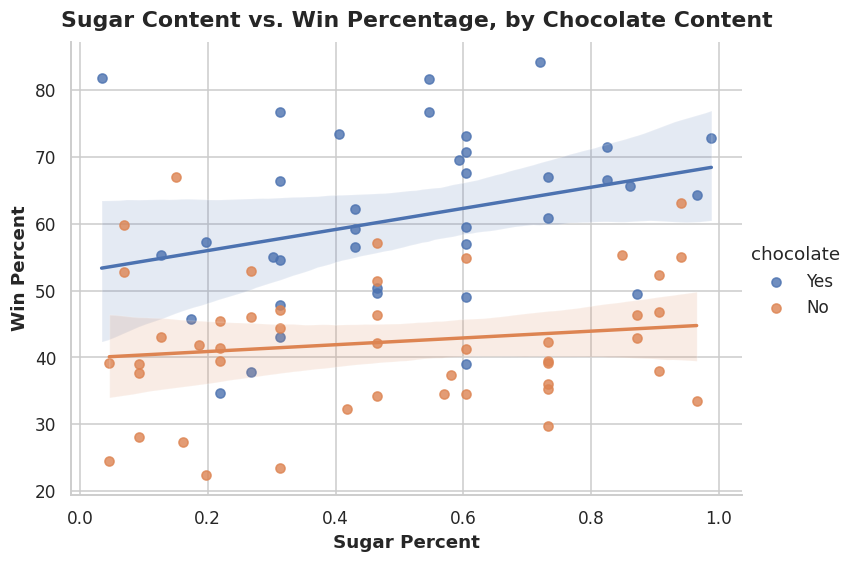

In [24]:
g = sns.lmplot(data=candy, x="sugarpercent", y="winpercent", hue="chocolate", height=5, aspect=1.4)
g.figure.suptitle("Sugar Content vs. Win Percentage, by Chocolate Content", y=1.02, fontweight="bold")
plt.xlabel("Sugar Percent", fontweight="bold")
plt.ylabel("Win Percent", fontweight="bold")
plt.show()

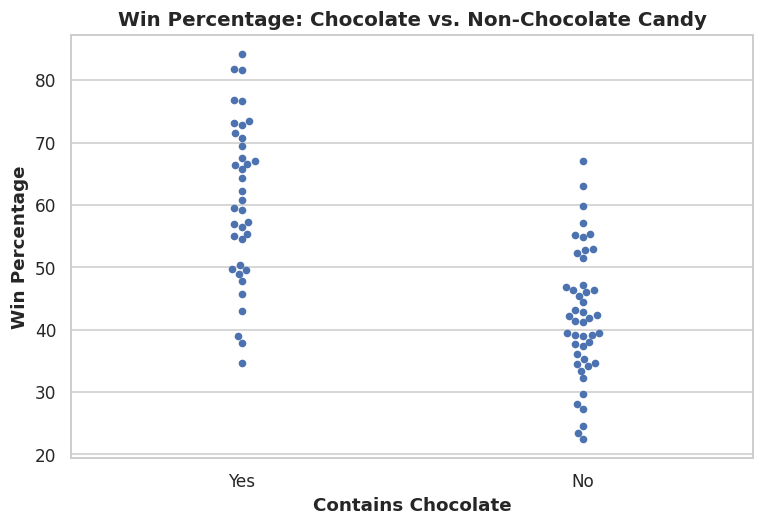

In [25]:
plt.figure(figsize=(8, 5))
plt.title("Win Percentage: Chocolate vs. Non-Chocolate Candy")
sns.swarmplot(data=candy, x="chocolate", y="winpercent")
plt.xlabel("Contains Chocolate", fontweight="bold")
plt.ylabel("Win Percentage", fontweight="bold")
plt.show()

**Takeaway:** Sugar content alone is only weakly related to popularity, but chocolate candies win noticeably more often than candies without chocolate.

## 4. Distributions: Histograms and KDE Plots

Distribution plots show how values are spread: where they cluster, how wide they range, and whether groups overlap.

### 4.1 Iris flowers

In [26]:
iris_data = pd.read_csv(data_dir / "iris.csv", index_col="Id")
iris_data.head()

,Sepal Length (cm),Sepal Width (cm),Petal Length (cm),Petal Width (cm),Species
Id,,,,,
1,5.1,3.5,1.4,0.2,Iris-setosa
2,4.9,3.0,1.4,0.2,Iris-setosa
3,4.7,3.2,1.3,0.2,Iris-setosa
4,4.6,3.1,1.5,0.2,Iris-setosa
5,5.0,3.6,1.4,0.2,Iris-setosa


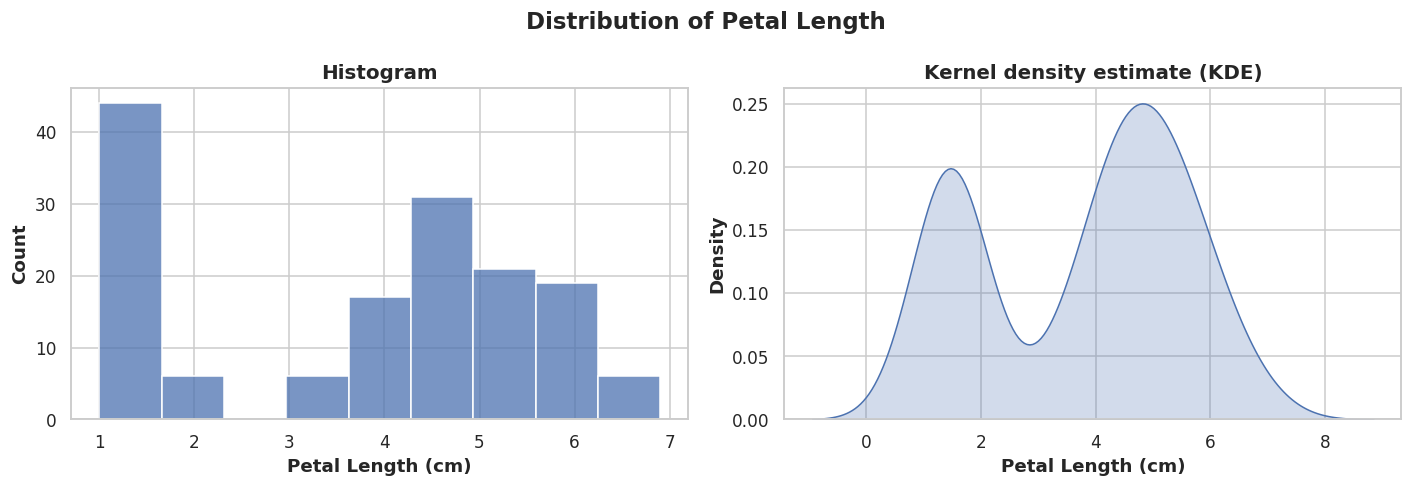

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(iris_data["Petal Length (cm)"], ax=axes[0])
axes[0].set_xlabel("Petal Length (cm)", fontweight="bold")
axes[0].set_ylabel("Count", fontweight="bold")
axes[0].set_title("Histogram")

sns.kdeplot(iris_data["Petal Length (cm)"], fill=True, ax=axes[1])
axes[1].set_xlabel("Petal Length (cm)", fontweight="bold")
axes[1].set_ylabel("Density", fontweight="bold")
axes[1].set_title("Kernel density estimate (KDE)")

axes[1].set_title("Kernel density estimate (KDE)")


fig.suptitle("Distribution of Petal Length", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

A 2D KDE with marginal distributions captures how two variables are distributed together:

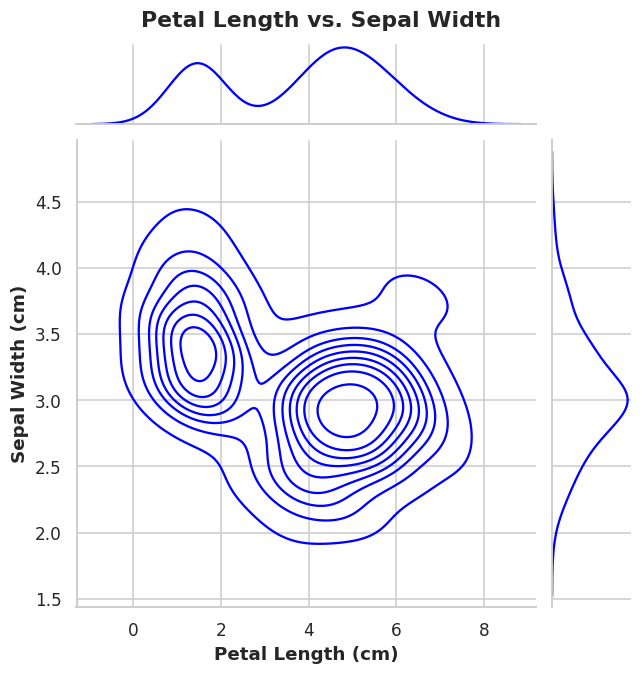

In [28]:
g = sns.jointplot(data=iris_data, x="Petal Length (cm)", y="Sepal Width (cm)", kind="kde", color="blue")
g.figure.suptitle("Petal Length vs. Sepal Width", y=1.02, fontweight="bold")
g.ax_joint.set_xlabel("Petal Length (cm)", fontweight="bold")
g.ax_joint.set_ylabel("Sepal Width (cm)", fontweight="bold")
plt.show()

Splitting by species shows how well each feature separates the classes:

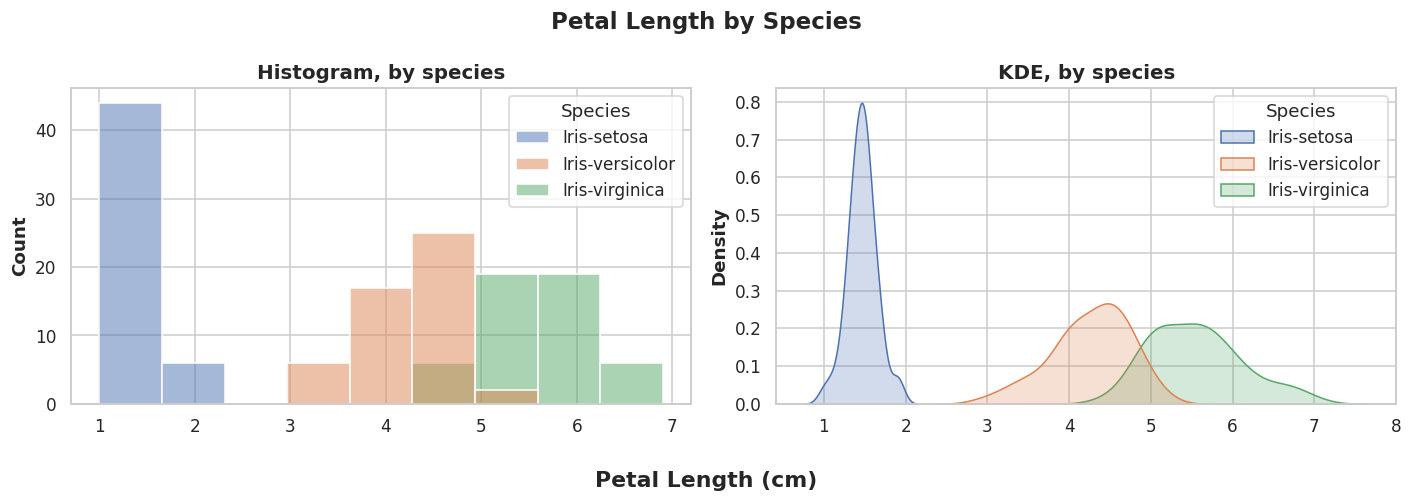

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=iris_data, x="Petal Length (cm)", hue="Species", ax=axes[0])
#axes[0].set_xlabel("Petal Length (cm)", fontweight="bold")
axes[0].set_ylabel("Count", fontweight="bold")
axes[0].set_title("Histogram, by species")

sns.kdeplot(data=iris_data, x="Petal Length (cm)", hue="Species", fill=True, ax=axes[1])
#axes[1].set_xlabel("Petal Length (cm)",fontweight="bold")
axes[1].set_ylabel("Density", fontweight="bold")
axes[1].set_title("KDE, by species")

fig.suptitle("Petal Length by Species", fontsize=15, fontweight="bold")
for ax in axes:
    ax.set_xlabel("")
    
fig.supxlabel("Petal Length (cm)", fontweight="bold")
plt.tight_layout()
plt.show()

**Takeaway:** Petal length cleanly separates *Iris-setosa* from the other two species, while *versicolor* and *virginica* overlap only slightly.

### 4.2 Breast cancer diagnostics
Tumour measurements for benign (`B`) and malignant (`M`) diagnoses.

In [30]:
cancer_data = pd.read_csv(data_dir / "cancer.csv", index_col="Id")
cancer_data.head()

,Diagnosis,Radius (mean),Texture (mean),Perimeter (mean),Area (mean),Smoothness (mean),Compactness (mean),Concavity (mean),Concave points (mean),Symmetry (mean),...,Radius (worst),Texture (worst),Perimeter (worst),Area (worst),Smoothness (worst),Compactness (worst),Concavity (worst),Concave points (worst),Symmetry (worst),Fractal dimension (worst)
Id,,,,,,,,,,,,,,,,,,,,,
8510426,B,13.540,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.047810,0.1885,...,15.110,19.26,99.70,711.2,0.14400,0.17730,0.23900,0.12880,0.2977,0.07259
8510653,B,13.080,15.71,85.63,520.0,0.10750,0.12700,0.04568,0.031100,0.1967,...,14.500,20.49,96.09,630.5,0.13120,0.27760,0.18900,0.07283,0.3184,0.08183
8510824,B,9.504,12.44,60.34,273.9,0.10240,0.06492,0.02956,0.020760,0.1815,...,10.230,15.66,65.13,314.9,0.13240,0.11480,0.08867,0.06227,0.2450,0.07773
854941,B,13.030,18.42,82.61,523.8,0.08983,0.03766,0.02562,0.029230,0.1467,...,13.300,22.81,84.46,545.9,0.09701,0.04619,0.04833,0.05013,0.1987,0.06169
85713702,B,8.196,16.84,51.71,201.9,0.08600,0.05943,0.01588,0.005917,0.1769,...,8.964,21.96,57.26,242.2,0.12970,0.13570,0.06880,0.02564,0.3105,0.07409


In [31]:
print(f"Largest mean perimeter: {cancer_data['Perimeter (mean)'].max():.2f}")
print(f"Smallest mean radius:   {cancer_data['Radius (mean)'].min():.3f}")

Largest mean perimeter: 188.50
Smallest mean radius:   6.981


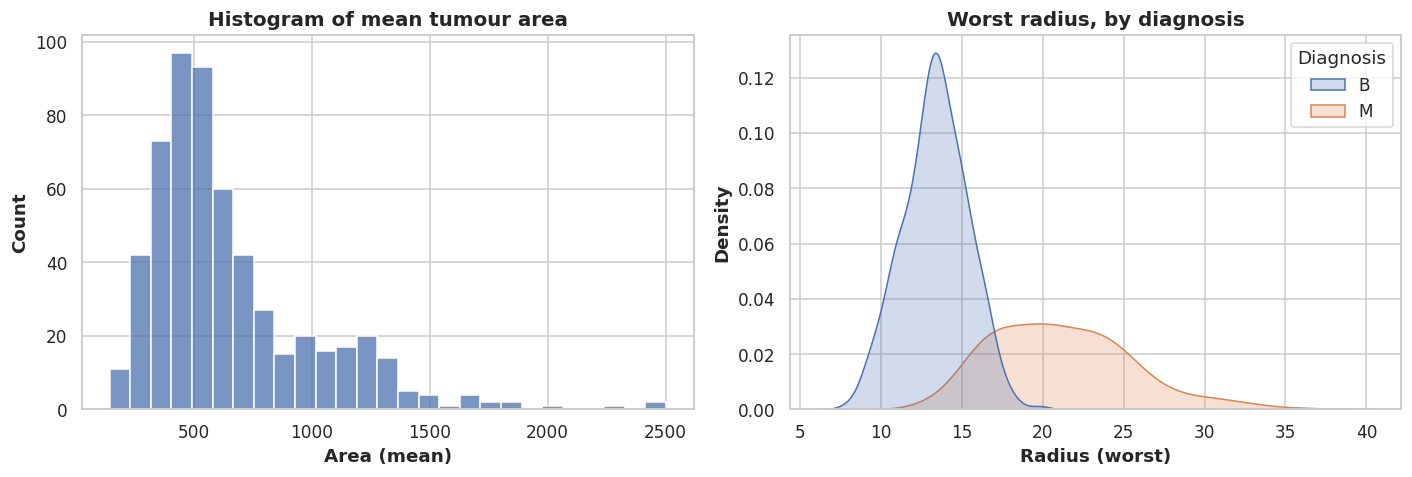

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(cancer_data["Area (mean)"], ax=axes[0])
axes[0].set_xlabel("Area (mean)", fontweight="bold")
axes[0].set_ylabel("Count", fontweight="bold")
axes[0].set_title("Histogram of mean tumour area")


sns.kdeplot(data=cancer_data, x="Radius (worst)", hue="Diagnosis", fill=True, ax=axes[1])
axes[1].set_xlabel("Radius (worst)", fontweight="bold")
axes[1].set_ylabel("Density", fontweight="bold")
axes[1].set_title("Worst radius, by diagnosis")

plt.tight_layout()
plt.show()

**Takeaway:** Malignant tumours (`M`) have a larger and much more variable worst radius than benign ones (`B`), making this a strong diagnostic feature.

## 5. Customising Style: Seaborn Themes

Themes change the look of a plot without touching the data. Here the same Spotify chart is shown in four built-in styles.

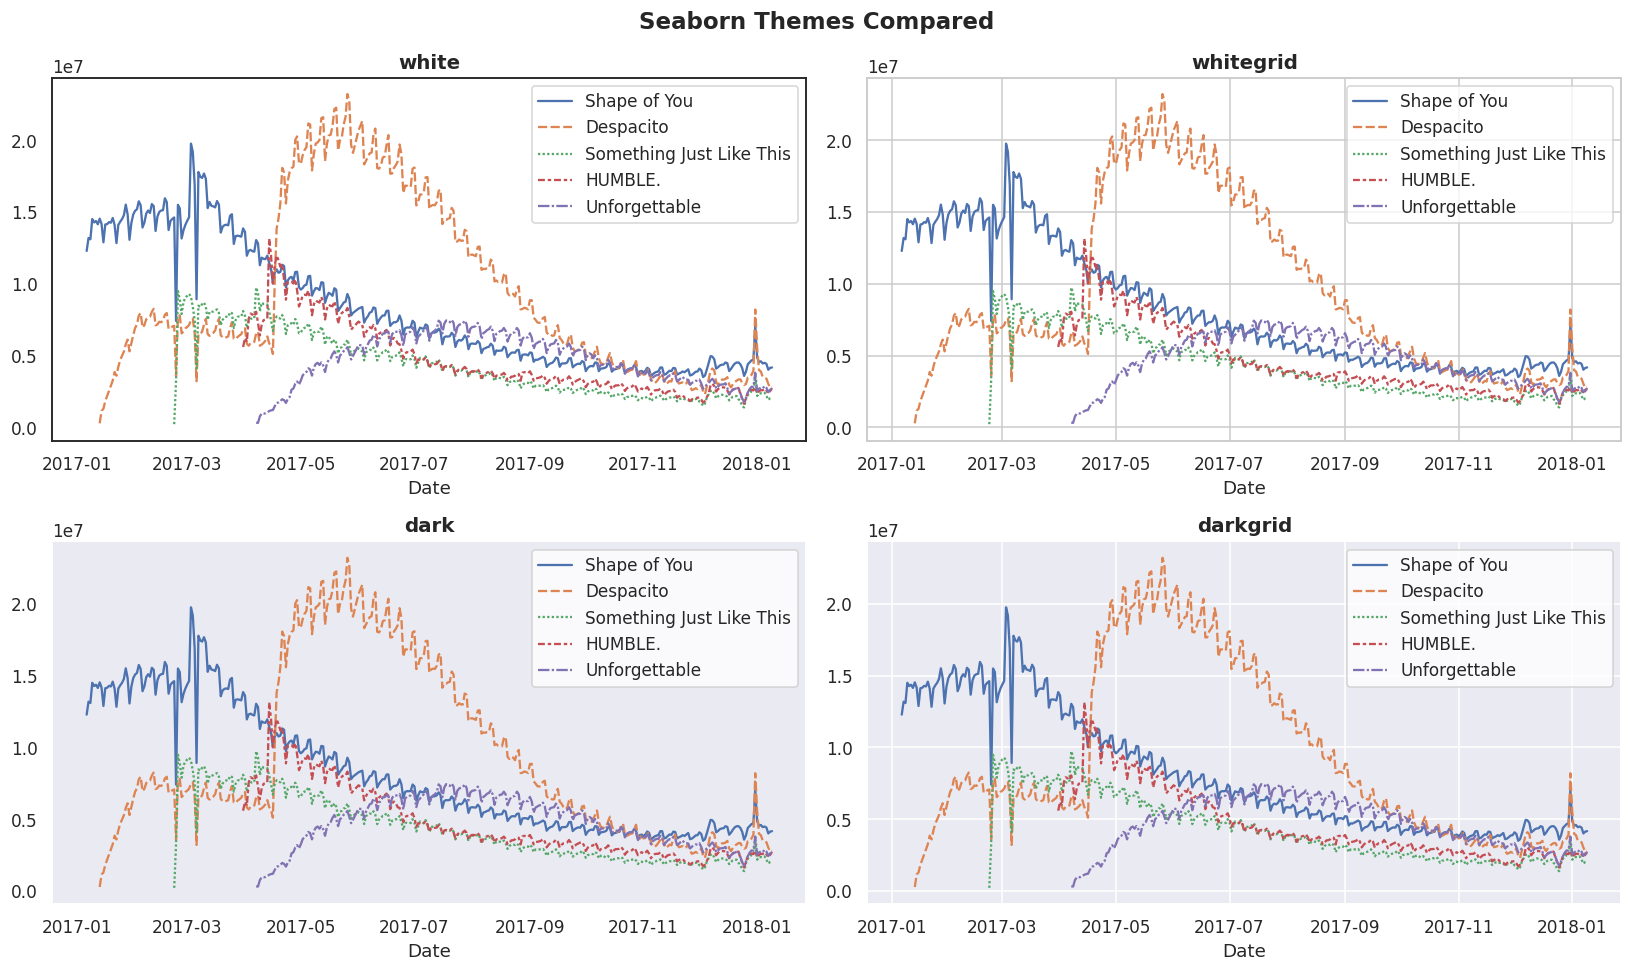

In [33]:
styles = ["white", "whitegrid", "dark", "darkgrid"]

fig = plt.figure(figsize=(15, 9))

for i, sty in enumerate(styles, start=1):
    with sns.axes_style(sty):
        ax = fig.add_subplot(2, 2, i)
        sns.lineplot(data=spotify_data, ax=ax, legend="full")
        ax.set_title(f'{sty}')
        leg = ax.get_legend()
        leg.get_frame().set_facecolor("white")

fig.suptitle("Seaborn Themes Compared", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Amazon Product Ratings and Discounts

Raw data is rarely plot-ready. This part cleans an Amazon product dataset, then explores how ratings and discounts behave.


### 6.1 Load and inspect

In [34]:
amazon = pd.read_csv(data_dir / "amazon.csv")
amazon.head(3)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...


### 6.2 Clean
Prices, discounts and counts are stored as text (for example `₹399` or `64%`). They are converted to numbers, and rows with missing values are dropped.

In [35]:
def to_number(series):
    """Strip currency symbols, commas and percent signs, then convert to float."""
    cleaned = series.astype(str).str.replace(r"[₹,%]", "", regex=True)
    return pd.to_numeric(cleaned, errors="coerce")  # invalid entries become NaN

df = amazon.copy()
for col in ["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"]:
    df[col] = to_number(df[col])

df["main_category"] = df["category"].str.split("|").str[0]

rows_before = len(df)
df = df.dropna(subset=["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"])
print(f"Kept {len(df):,} of {rows_before:,} rows after cleaning")
df[["discounted_price", "actual_price", "discount_percentage", "rating", "rating_count"]].isna().sum()

Kept 1,462 of 1,465 rows after cleaning


discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
dtype: int64

### 6.3 Explore

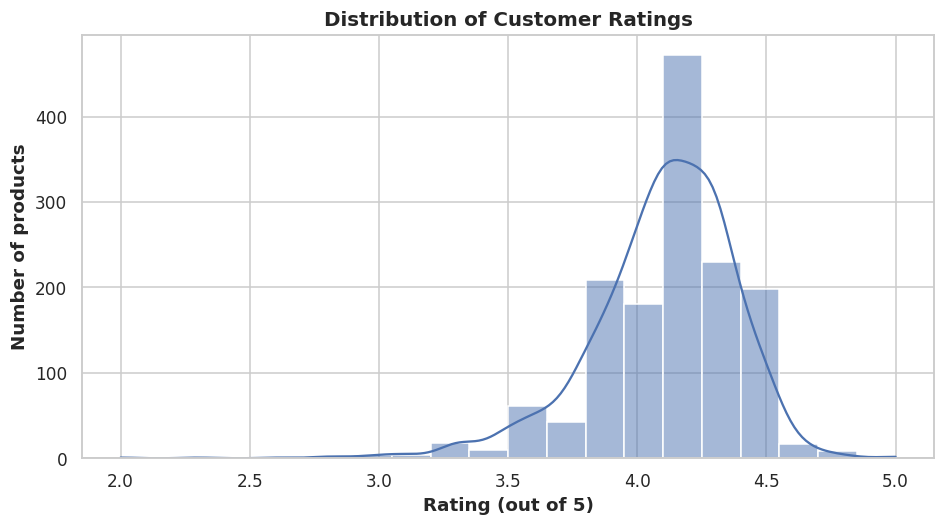

In [36]:
plt.figure(figsize=(10, 5))
plt.title("Distribution of Customer Ratings")
sns.histplot(df["rating"], bins=20, kde=True)
plt.xlabel("Rating (out of 5)", fontweight="bold")
plt.ylabel("Number of products", fontweight="bold")
plt.show()

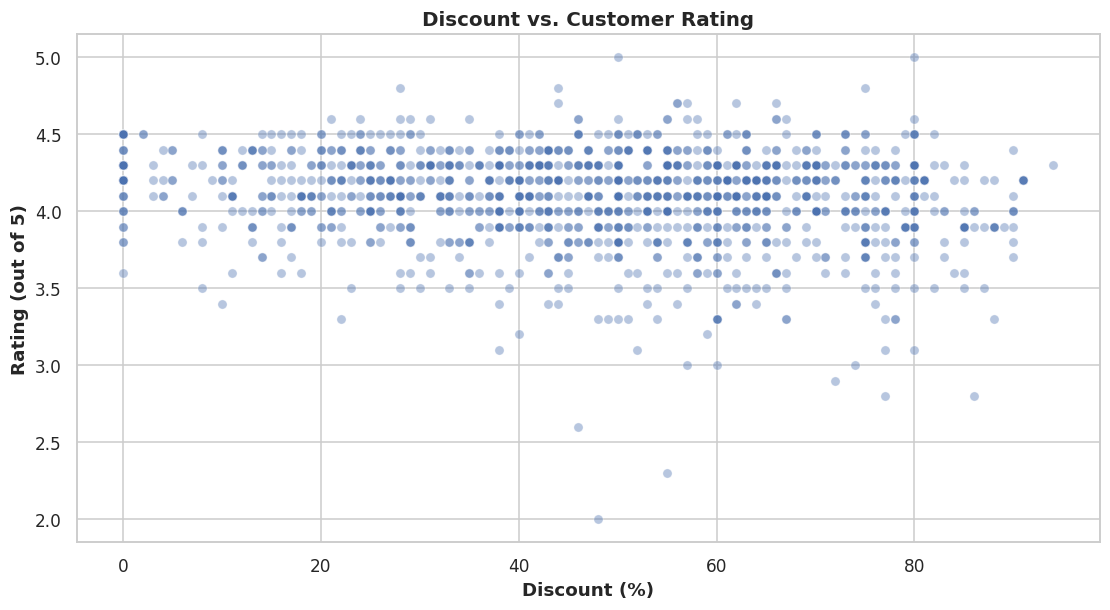

In [37]:
plt.figure(figsize=(12, 6))
plt.title("Discount vs. Customer Rating")
sns.scatterplot(data=df, x="discount_percentage", y="rating", alpha=0.4)
plt.xlabel("Discount (%)", fontweight="bold")
plt.ylabel("Rating (out of 5)", fontweight="bold")
plt.show()

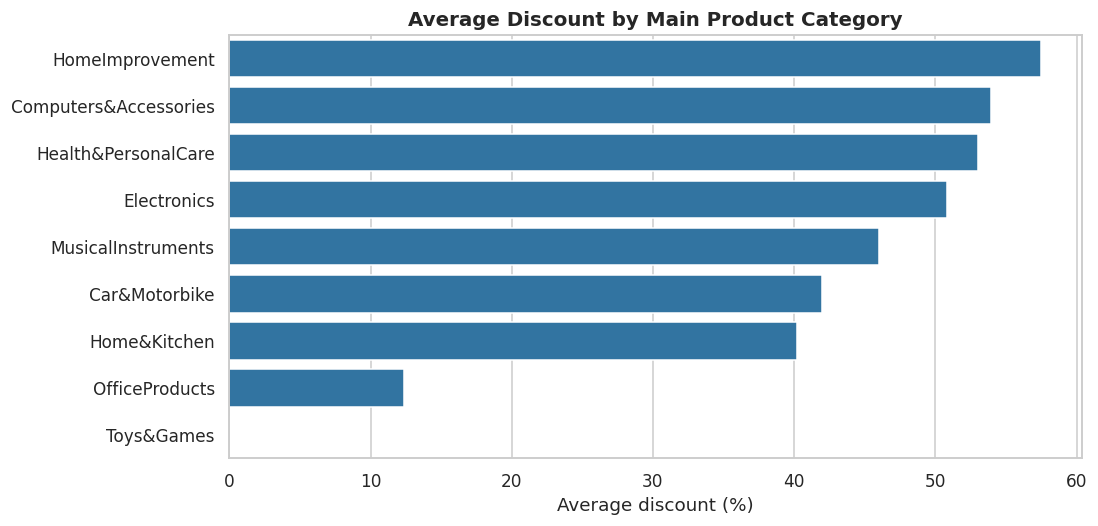

In [38]:
category_discount = (
    df.groupby("main_category")["discount_percentage"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))
plt.title("Average Discount by Main Product Category")
sns.barplot(data=category_discount, x="discount_percentage", y="main_category", color="tab:blue")
plt.xlabel("Average discount (%)")
plt.ylabel("")
plt.show()

**Findings:** Ratings cluster tightly between roughly 3.8 and 4.5, so most products are well reviewed. The scatter plot shows no strong link between discount size and rating, so deeper discounts do not appear to signal better or worse quality. Discount depth does vary noticeably across categories.